<a href="https://colab.research.google.com/github/Antx0x/PMP-2026/blob/main/Tema6_Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tema 6 - Laboratorul 7
## Inferenta Bayesiana si simulare probabilistica



- `numpy` - calcule numerice si numere aleatoare
- `scipy.stats` - distributii de probabilitate (Beta, Binomial)
- `scipy.special` - functia Beta (pentru predictie)
- `matplotlib` - grafice

In [1]:
import numpy as np
from scipy import stats
from scipy import special
import matplotlib.pyplot as plt

print(" import cu succes")

 import cu succes


---
# Exercitiul 1 - Controlul calitatii (inferenta Bayesiana)

**Datele problemei:**
- $\theta$ = probabilitatea ca o componenta sa fie defecta (necunoscuta)
- distributia a priori: $\theta \sim \text{Beta}(2, 18)$
- s-au testat $n = 50$ componente, dintre care $y = 8$ sunt defecte

Intai salvam aceste date in variabile Python.

In [ ]:
a_prior = 2
b_prior = 18

n = 50
y = 8

print("A priori: Beta(", a_prior, ",", b_prior, ")")
print("Date: n =", n, ", y =", y)

A priori: Beta( 2 , 18 )
Date: n = 50 , y = 8


## a) Modelul probabilistic

Fiecare componenta testata este fie defecta (cu probabilitatea $\theta$), fie buna (cu probabilitatea $1-\theta$), iar testele sunt independente (conditionat de $\theta$).

Numarul de "succese" (aici: defecte) din $n$ incercari independente, fiecare cu aceeasi probabilitate $\theta$, urmeaza o **distributie binomiala**:

$$Y \mid \theta \sim \text{Binomial}(n = 50,\ \theta)$$

**Functia de verosimilitate** este probabilitatea datelor observate, privita ca functie de $\theta$:

$$L(\theta) = P(Y = y \mid \theta) = \binom{n}{y}\,\theta^{y}\,(1-\theta)^{n-y} = \binom{50}{8}\,\theta^{8}\,(1-\theta)^{42}, \qquad \theta \in [0,1].$$

Mai jos calculam aceasta functie pentru cateva valori ale lui $\theta$, ca sa vedem cum arata.

In [ ]:
def verosimilitate(theta):
    return stats.binom.pmf(y, n, theta)

for theta in [0.05, 0.10, 0.16, 0.20, 0.30]:
    print(f"theta = {theta:.2f}  ->  P(Y=8 | theta) = {verosimilitate(theta):.5f}")

theta = 0.16
manual = special.comb(50, 8) * theta**8 * (1 - theta)**42
print("\nVerificare cu formula pentru theta=0.16:", round(manual, 5))

theta = 0.05  ->  P(Y=8 | theta) = 0.00243
theta = 0.10  ->  P(Y=8 | theta) = 0.06428
theta = 0.16  ->  P(Y=8 | theta) = 0.15225
theta = 0.20  ->  P(Y=8 | theta) = 0.11692
theta = 0.30  ->  P(Y=8 | theta) = 0.01099

Verificare cu formula pentru theta=0.16: 0.15225


Observam ca verosimilitatea este cea mai mare in jurul lui $\theta = 0.16 = 8/50$

## b) Actualizarea Bayesiana (distributia a posteriori)

**Formula lui Bayes** pentru o densitate:

$$p(\theta \mid y) = \frac{P(y \mid \theta)\, p(\theta)}{P(y)} \;\propto\; P(y \mid \theta)\, p(\theta).$$

Numitorul $P(y)$ nu depinde de $\theta$, deci e doar o constanta de normalizare (semnul $\propto$ inseamna "proportional cu").

**Densitatea a priori** $\text{Beta}(a, b)$:
$$p(\theta) = \frac{1}{B(a,b)}\,\theta^{a-1}(1-\theta)^{b-1} \;\propto\; \theta^{2-1}(1-\theta)^{18-1} = \theta^{1}(1-\theta)^{17}.$$

**Inmultim** verosimilitatea cu a priori-ul (pastram doar ce depinde de $\theta$):
$$p(\theta \mid y) \;\propto\; \underbrace{\theta^{8}(1-\theta)^{42}}_{\text{verosimilitate}} \cdot \underbrace{\theta^{1}(1-\theta)^{17}}_{\text{a priori}} = \theta^{9}(1-\theta)^{59}.$$

Expresia $\theta^{9}(1-\theta)^{59}$ este exact "miezul" unei densitati Beta cu $a-1 = 9$ si $b-1 = 59$, adica:

$$\boxed{\theta \mid Y = 8 \;\sim\; \text{Beta}(a + y,\; b + n - y) = \text{Beta}(2+8,\; 18+42) = \text{Beta}(10,\ 60)}$$

 a priori-ul Beta(2, 18) e ca si cum am fi vazut deja "2 defecte din 20 de componente"; acum adaugam 8 defecte din 50, deci in total "10 defecte din 70".

In [ ]:
a_post = a_prior + y
b_post = b_prior + (n - y)

print("A posteriori: Beta(", a_post, ",", b_post, ")")

A posteriori: Beta( 10 , 60 )


**Verificare numerica:** calculam a posteriori-ul "brut", inmultind punct cu punct verosimilitatea cu a priori-ul pe o grila de valori si normalizand. Daca teoria e corecta, trebuie sa obtinem aceeasi curba ca Beta(10, 60).

In [ ]:
grila = np.linspace(0, 1, 2001)
nenormalizat = verosimilitate(grila) * stats.beta.pdf(grila, a_prior, b_prior)
pas = grila[1] - grila[0]
posterior_numeric = nenormalizat / (nenormalizat.sum() * pas)

posterior_teoretic = stats.beta.pdf(grila, a_post, b_post)
print("Diferenta maxima dintre cele doua curbe:", np.max(np.abs(posterior_numeric - posterior_teoretic)))

Diferenta maxima dintre cele doua curbe: 4.796163466380676e-14


Diferenta este practic zero (doar erori de rotunjire), deci rezultatul teoretic Beta(10, 60) este confirmat.

## c) Estimarea parametrului: MLE, MAP si media a posteriori

**1. Estimatorul de maxima verosimilitate (MLE)** - valoarea lui $\theta$ care maximizeaza $L(\theta)$.
$$\ell(\theta) = \ln L(\theta) = \text{const} + y\ln\theta + (n-y)\ln(1-\theta)$$
$$\ell'(\theta) = \frac{y}{\theta} - \frac{n-y}{1-\theta} = 0 \;\Rightarrow\; y(1-\theta) = (n-y)\theta \;\Rightarrow\; \hat\theta_{MLE} = \frac{y}{n} = \frac{8}{50} = 0.16$$

**2. Estimatorul MAP (maximum a posteriori)** - modul (varful) distributiei a posteriori. Pentru $\text{Beta}(\alpha,\beta)$ cu $\alpha,\beta>1$, maximizand $(\alpha-1)\ln\theta + (\beta-1)\ln(1-\theta)$ exact ca mai sus, obtinem:
$$\hat\theta_{MAP} = \frac{\alpha - 1}{\alpha + \beta - 2} = \frac{10-1}{10+60-2} = \frac{9}{68} \approx 0.1324$$

**3. Media a posteriori** - media unei distributii $\text{Beta}(\alpha,\beta)$ este $\frac{\alpha}{\alpha+\beta}$:
$$E[\theta \mid y] = \frac{10}{10 + 60} = \frac{10}{70} \approx 0.1429$$

In [ ]:
mle   = y / n
map_  = (a_post - 1) / (a_post + b_post - 2)
media = a_post / (a_post + b_post)
media_prior = a_prior / (a_prior + b_prior)

print(f"Media a priori         = {media_prior:.4f}")
print(f"MLE                    = {mle:.4f}")
print(f"MAP                    = {map_:.4f}")
print(f"Media a posteriori     = {media:.4f}")

# Verificare: media calculata de scipy
print(f"\nVerificare scipy: media Beta(10,60) = {stats.beta.mean(a_post, b_post):.4f}")
# Verificare MAP: cautam varful densitatii pe grila
print(f"Verificare MAP pe grila: {grila[np.argmax(posterior_teoretic)]:.4f}")

Media a priori         = 0.1000
MLE                    = 0.1600
MAP                    = 0.1324
Media a posteriori     = 0.1429

Verificare scipy: media Beta(10,60) = 0.1429
Verificare MAP pe grila: 0.1325


**Comparatie si explicatie:**

| Estimator | Valoare | Ce foloseste |
|---|---|---|
| Media a priori | 0.100 | doar experienta anterioara |
| MAP | 0.132 | a priori + date (varful) |
| Media a posteriori | 0.143 | a priori + date (media) |
| MLE | 0.160 | doar datele |

- **MLE** foloseste **doar datele** (8 din 50), deci e 0.16.
- **MAP** si **media a posteriori** combina datele cu a priori-ul. A priori-ul spunea ca rata e in jur de $2/20 = 0.10$, deci "trage" estimarea in jos, spre 0.10. De aceea ambele sunt intre 0.10 si 0.16.
- Media a posteriori se poate scrie ca **medie ponderata** intre media a priori si MLE:
$$E[\theta\mid y] = \frac{a+b}{a+b+n}\cdot\frac{a}{a+b} + \frac{n}{a+b+n}\cdot\frac{y}{n} = \frac{20}{70}\cdot 0.10 + \frac{50}{70}\cdot 0.16 \approx 0.143$$
  Datele au pondere $50/70 \approx 71\%$, a priori-ul $20/70 \approx 29\%$.
- **MAP < media** pentru ca distributia Beta(10, 60) este asimetrica, cu o "coada" spre dreapta: varful e mai la stanga decat media.
- Daca am avea foarte multe date ($n$ mare), toate trei s-ar apropia de aceeasi valoare.

In [ ]:
# Verificam formula mediei ponderate
w_prior = (a_prior + b_prior) / (a_prior + b_prior + n)
w_date  = n / (a_prior + b_prior + n)
print(f"Ponderea a priori-ului = {w_prior:.3f}, ponderea datelor = {w_date:.3f}")
print(f"Medie ponderata = {w_prior * media_prior + w_date * mle:.4f}  (trebuie sa fie egala cu media a posteriori {media:.4f})")

Ponderea a priori-ului = 0.286, ponderea datelor = 0.714
Medie ponderata = 0.1429  (trebuie sa fie egala cu media a posteriori 0.1429)


## d) Vizualizare: a priori vs a posteriori
Desenam pe acelasi grafic densitatea a priori Beta(2, 18) si densitatea a posteriori Beta(10, 60). Marcam si cele trei estimari cu linii verticale.

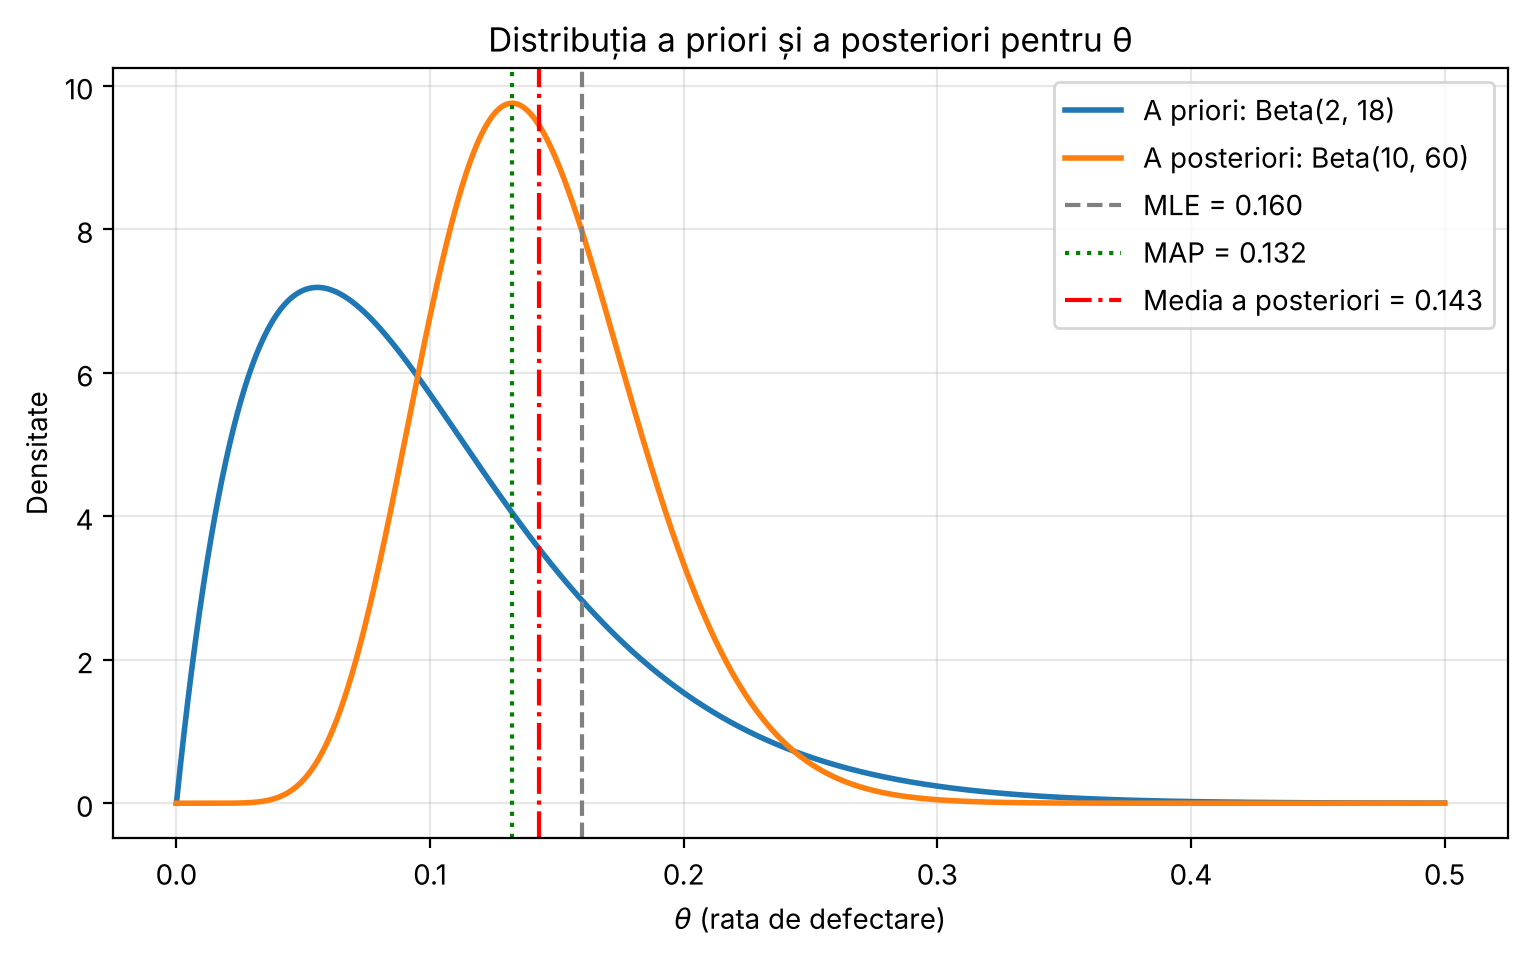

In [ ]:
x = np.linspace(0, 0.5, 1000)   # rata de defectare nu are sens sa o desenam pana la 1, curbele sunt ~0 dupa 0.4

plt.figure(figsize=(9, 5))
plt.plot(x, stats.beta.pdf(x, a_prior, b_prior), label="A priori: Beta(2, 18)", linewidth=2)
plt.plot(x, stats.beta.pdf(x, a_post, b_post),   label="A posteriori: Beta(10, 60)", linewidth=2)

plt.axvline(mle,   color="gray",  linestyle="--", label=f"MLE = {mle:.3f}")
plt.axvline(map_,  color="green", linestyle=":",  label=f"MAP = {map_:.3f}")
plt.axvline(media, color="red",   linestyle="-.", label=f"Media a posteriori = {media:.3f}")

plt.xlabel(r"$\theta$ (rata de defectare)")
plt.ylabel("Densitate")
plt.title("Distributia a priori si a posteriori pentru theta")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Cat de "lata" e fiecare distributie? (deviatia standard)
print(f"Deviatia standard a priori:     {stats.beta.std(a_prior, b_prior):.4f}")
print(f"Deviatia standard a posteriori: {stats.beta.std(a_post, b_post):.4f}")

Deviatia standard a priori:     0.0655
Deviatia standard a posteriori: 0.0415


**Ce s-a schimbat dupa observarea datelor?**
- **Pozitia:** curba s-a mutat spre dreapta - datele (16% defecte) arata o rata mai mare decat credeam initial (~10%).
- **Forma:** curba a posteriori e mult mai **ingusta si mai inalta** (deviatia standard scade de la ~0.065 la ~0.042). Asta inseamna ca suntem **mai siguri** pe valoarea lui $\theta$ dupa ce am vazut 50 de componente.
- Pe scurt: datele au mutat informatia spre rate de defectare mai mari si au redus incertitudinea.

## e) Interval credibil central de 95%

Un interval credibil central de 95% $[q_{0.025},\ q_{0.975}]$ lasa cate 2.5% din probabilitatea a posteriori in fiecare capat:
$$P(q_{0.025} \le \theta \le q_{0.975} \mid y) = 0.95.$$
Capetele sunt **cuantilele** distributiei Beta(10, 60), pe care le calculam cu `stats.beta.ppf` (inversa functiei de repartitie).

In [ ]:
stanga  = stats.beta.ppf(0.025, a_post, b_post)
dreapta = stats.beta.ppf(0.975, a_post, b_post)
print(f"Interval credibil 95%: [{stanga:.4f}, {dreapta:.4f}]")

print("Verificare:", stats.beta.cdf(dreapta, a_post, b_post) - stats.beta.cdf(stanga, a_post, b_post))

print("Cu stats.beta.interval:", stats.beta.interval(0.95, a_post, b_post))

Interval credibil 95%: [0.0717, 0.2332]
Verificare: 0.9500000000000001
Cu stats.beta.interval: (np.float64(0.07174913989206377), np.float64(0.2332189597948612))


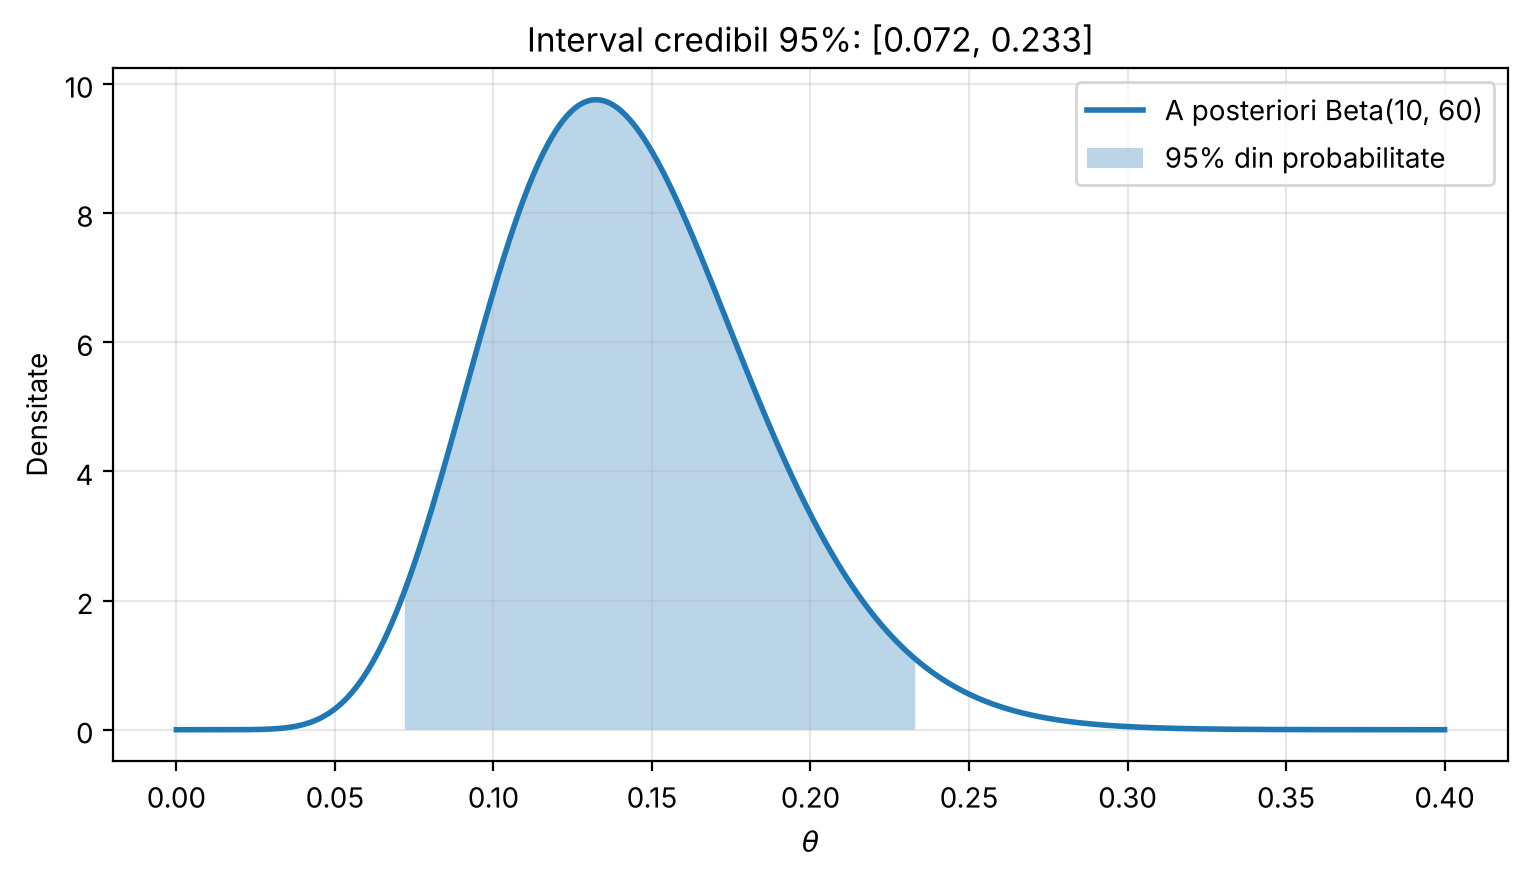

In [ ]:
x = np.linspace(0, 0.4, 1000)
dens = stats.beta.pdf(x, a_post, b_post)
plt.figure(figsize=(9, 4.5))
plt.plot(x, dens, linewidth=2, label="A posteriori Beta(10, 60)")
zona = (x >= stanga) & (x <= dreapta)
plt.fill_between(x[zona], dens[zona], alpha=0.3, label="95% din probabilitate")
plt.xlabel(r"$\theta$"); plt.ylabel("Densitate")
plt.title(f"Interval credibil 95%: [{stanga:.3f}, {dreapta:.3f}]")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretare:** Intervalul este aproximativ **[0.072, 0.233]**. Avand in vedere a priori-ul si datele observate, exista o probabilitate de 95% ca rata reala de defectare sa fie intre circa **7.2% si 23.3%**.

Spre deosebire de intervalul de incredere din statistica clasica, aici putem spune direct "$\theta$ se afla in interval cu probabilitate 95%", pentru ca in abordarea Bayesiana $\theta$ are o distributie. Intervalul e destul de larg - 50 de componente nu sunt suficiente pentru o estimare foarte precisa.

## f) Decizie practica: este rata de defectare sub 10%?

Calculam probabilitatea a posteriori
$$P(\theta < 0.10 \mid Y = 8) = \int_0^{0.10} p(\theta \mid y)\, d\theta = F_{\text{Beta}(10,60)}(0.10),$$
adica functia de repartitie (CDF) a posteriori-ului in punctul 0.10.

In [ ]:
p_sub_10 = stats.beta.cdf(0.10, a_post, b_post)
print(f"P(theta < 0.10 | Y = 8) = {p_sub_10:.4f}  (aprox. {100*p_sub_10:.1f}%)")
print(f"P(theta >= 0.10 | Y = 8) = {1 - p_sub_10:.4f}")

p_sub_10_prior = stats.beta.cdf(0.10, a_prior, b_prior)
print(f"\nPentru comparatie, a priori: P(theta < 0.10) = {p_sub_10_prior:.4f}")

P(theta < 0.10 | Y = 8) = 0.1484  (aprox. 14.8%)
P(theta >= 0.10 | Y = 8) = 0.8516

Pentru comparatie, a priori: P(theta < 0.10) = 0.5797


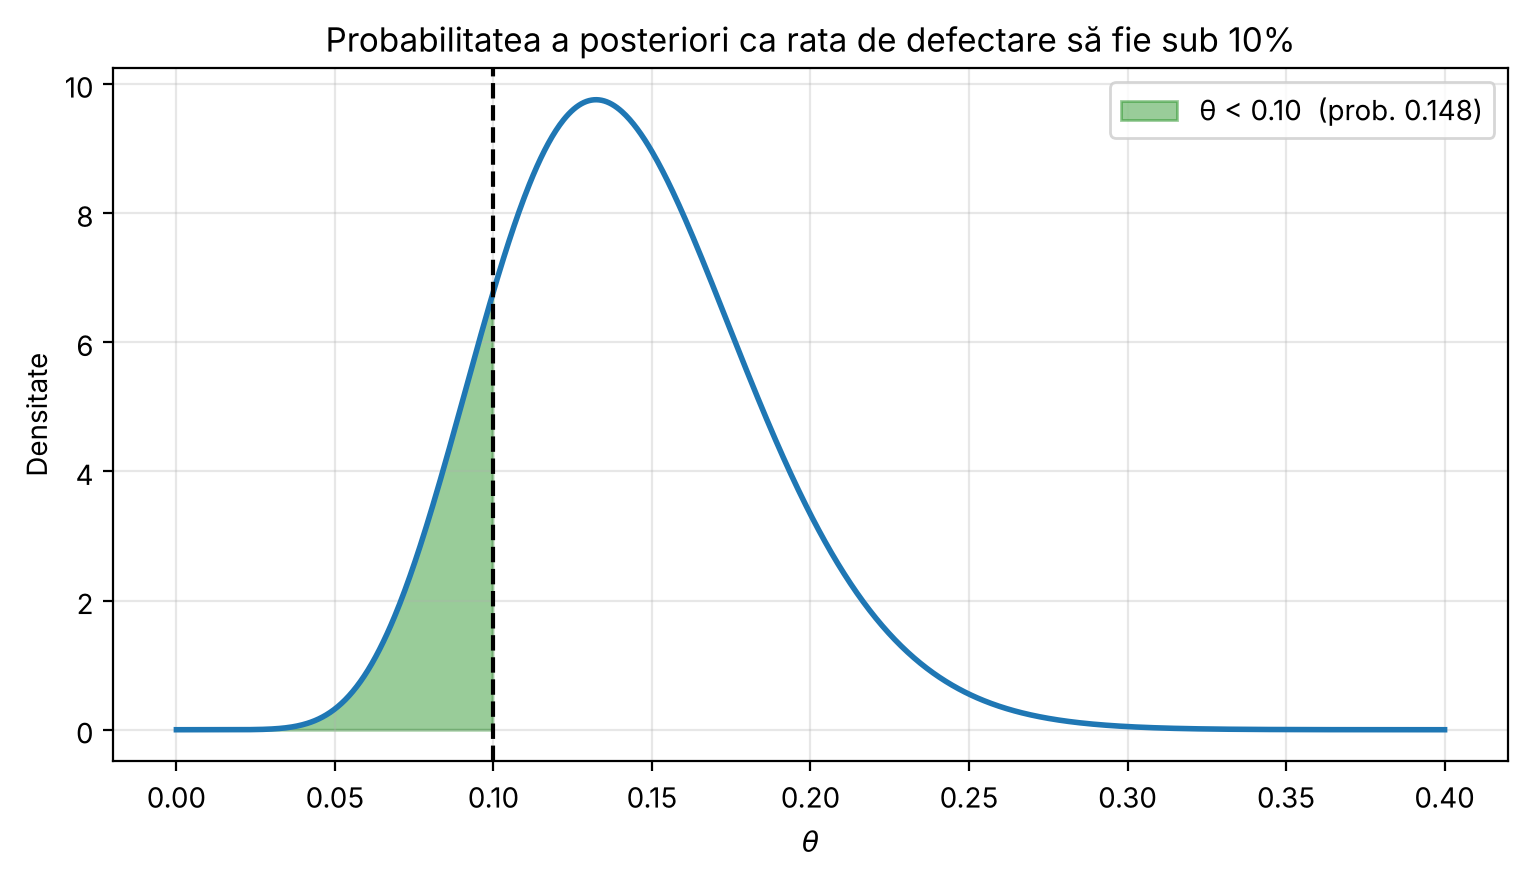

In [ ]:
x = np.linspace(0, 0.4, 1000)
dens = stats.beta.pdf(x, a_post, b_post)
plt.figure(figsize=(9, 4.5))
plt.plot(x, dens, linewidth=2)
plt.fill_between(x[x < 0.10], dens[x < 0.10], color="green", alpha=0.4, label=f"theta < 0.10  (prob. {p_sub_10:.3f})")
plt.axvline(0.10, color="black", linestyle="--")
plt.xlabel(r"$\theta$"); plt.ylabel("Densitate")
plt.title("Probabilitatea a posteriori ca rata de defectare sa fie sub 10%")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretare:** $P(\theta < 0.10 \mid Y=8) \approx 0.148$, adica doar aproximativ **15%**. Cu alte cuvinte, exista o probabilitate de ~85% ca rata de defectare sa fie **peste** 10%.

Inainte de date, aceasta probabilitate era ~59%; datele au redus-o mult. Concluzie: **datele nu sustin cerinta** ca rata de defectare sa fie sub 10%. Fabrica ar trebui sa investigheze procesul de productie (sau sa testeze mai multe componente daca vrea o concluzie mai sigura).







# Exercitiul 2 - Restaurant fast-food (simulare Monte Carlo)

**Datele problemei:**
- clientii sosesc dupa un **proces Poisson** cu $\lambda = 20$ clienti/ora $= 1/3$ clienti/minut
- timpul de **plata** la casa: exponential cu media **2 minute**
- timpul de **preparare** la bucatarie: exponential cu media **$\alpha$ minute**
- o singura casa, o singura statie de gatit, ambele FIFO (primul venit - primul servit)
- simulam clientii sositi in intervalul $[0, 60]$ minute si ii urmarim pana primesc mancarea

### Idei de baza, pe scurt
- Intr-un proces Poisson cu intensitatea $\lambda$, **timpii dintre doua sosiri consecutive** sunt independenti, exponentiali cu media $1/\lambda = 3$ minute. Deci generam sosirile adunand pe rand timpi exponentiali cu media 3, pana depasim 60 de minute.
- In `numpy`, `rng.exponential(scale)` primeste **media** (scale), nu rata.

In [ ]:
lam_pe_ora = 20
media_intre_sosiri = 60 / lam_pe_ora   # 3 minute
media_plata = 2                         # minute
DURATA = 60
PRAG = 15

print("Timp mediu intre sosiri:", media_intre_sosiri, "minute")

Timp mediu intre sosiri: 3.0 minute


## a) Simularea unei ore

Clientii trec prin doua etape, in ordine: **casa** -> **bucataria**. Ambele sunt FIFO, deci clientii sunt serviti in ordinea sosirii (si ordinea se pastreaza de la casa la bucatarie).

Pentru clientul $i$ (in ordinea sosirii) notam:
- $S_i$ = momentul sosirii, $P_i$ = timpul de plata, $G_i$ = timpul de preparare

**Coada 1 - casa.** Clientul poate incepe plata doar cand a sosit **si** casa e libera (clientul anterior a terminat de platit)

**Coada 2 - bucataria.** Comanda intra in coada bucatariei imediat dupa plata. Prepararea incepe cand comanda e plasata **si** bucataria e libera

Timpul de **asteptare efectiva** (fara servire) = timp total - timp de plata - timp de gatit:
$$W_i = T_i - P_i - G_i

In [ ]:
def simuleaza_o_ora(alfa, rng):
    '''
    Simuleaza
    '''
    sosiri = []
    t = 0.0
    while True:
        t = t + rng.exponential(media_intre_sosiri)   # timpul pana la urmatorul client
        if t > DURATA:                                 # a sosit dupa minutul 60 - nu-l mai luam
            break
        sosiri.append(t)
    sosiri = np.array(sosiri)
    nr_clienti = len(sosiri)

    #generam timpii de plata si de preparare
    plata = rng.exponential(media_plata, size=nr_clienti)
    gatit = rng.exponential(alfa, size=nr_clienti)

    #trecem clientii prin cele doua cozi (FIFO)
    start_plata   = np.zeros(nr_clienti)
    sfarsit_plata = np.zeros(nr_clienti)
    start_gatit   = np.zeros(nr_clienti)
    sfarsit_gatit = np.zeros(nr_clienti)

    casa_libera_la = 0.0        # la inceput sistemul e gol
    bucatarie_libera_la = 0.0

    for i in range(nr_clienti):
        # coada 1: casa
        start_plata[i] = max(sosiri[i], casa_libera_la)
        sfarsit_plata[i] = start_plata[i] + plata[i]
        casa_libera_la = sfarsit_plata[i]

        # coada 2: bucataria
        start_gatit[i] = max(sfarsit_plata[i], bucatarie_libera_la)
        sfarsit_gatit[i] = start_gatit[i] + gatit[i]
        bucatarie_libera_la = sfarsit_gatit[i]

    timp_total = sfarsit_gatit - sosiri          # de la sosire pana primeste mancarea
    asteptare  = timp_total - plata - gatit       # doar timpul petrecut la coada

    return {
        "sosiri": sosiri, "plata": plata, "gatit": gatit,
        "start_plata": start_plata, "sfarsit_plata": sfarsit_plata,
        "start_gatit": start_gatit, "primeste_mancarea": sfarsit_gatit,
        "timp_total": timp_total, "asteptare": asteptare,
    }

Testam functia pe o singura ora, de exemplu cu $\alpha = 1$ minut, si afisam un tabel cu primii clienti.

In [ ]:
rng = np.random.default_rng(2026)
ora = simuleaza_o_ora(alfa=1.0, rng=rng)

print("Numar de clienti sositi:", len(ora["sosiri"]))
print()
print(f"{'Client':>6} {'Sosire':>8} {'Start plata':>12} {'Gata plata':>11} {'Start gatit':>12} {'Primeste':>9} {'Timp total':>11}")
for i in range(min(10, len(ora["sosiri"]))):
    print(f"{i+1:>6} {ora['sosiri'][i]:>8.2f} {ora['start_plata'][i]:>12.2f} {ora['sfarsit_plata'][i]:>11.2f} "
          f"{ora['start_gatit'][i]:>12.2f} {ora['primeste_mancarea'][i]:>9.2f} {ora['timp_total'][i]:>11.2f}")

print("\nTimpul maxim de servire in aceasta ora:", round(ora["timp_total"].max(), 2), "minute")
print("Toti clientii au primit mancarea in <= 15 minute?", bool(np.all(ora["timp_total"] <= PRAG)))

NameError: name 'np' is not defined

Verificare rapida a logicii: in tabel, fiecare "Start plata" este >= "Sosire" si >= "Gata plata" al clientului anterior; fiecare "Start gatit" este >= "Gata plata" al aceluiasi client si >= "Primeste" al clientului anterior. Asta confirma ca cele doua cozi FIFO functioneaza corect.

In [ ]:
assert np.all(ora["start_plata"] >= ora["sosiri"])
assert np.all(ora["start_plata"][1:] >= ora["sfarsit_plata"][:-1] - 1e-12)
assert np.all(ora["start_gatit"] >= ora["sfarsit_plata"])
assert np.all(ora["start_gatit"][1:] >= ora["primeste_mancarea"][:-1] - 1e-12)
assert np.all(ora["asteptare"] >= -1e-12)
print("Toate verificarile au trecut.")

Toate verificarile au trecut.


## b) Probabilitatea ca **toti** clientii sa fie serviti in <= 15 minute

**Atentie (din enunt):** conditia se refera la **toti clientii dintr-o ora**. Deci o ora este "reusita" daca **fiecare** client sosit in acea ora primeste mancarea in cel mult 15 minute ($\max_i T_i \le 15$). Daca intr-o ora nu soseste niciun client, o consideram reusita (nu e nimeni care sa astepte prea mult).

**Estimarea Monte Carlo:** repetam simularea de $N$ ori si numaram cate ore sunt reusite:
$$\hat p(\alpha) = \frac{\text{nr. de ore reusite}}{N}.$$
Eroarea standard a acestei estimari este $\sqrt{\hat p(1-\hat p)/N}$, deci cu $N = 10\,000$ eroarea e de circa $\pm 0.004$.

Calculam in paralel si probabilitatea ca **un client ales aleatoriu** sa fie servit in 15 minute (proportia tuturor clientilor serviti la timp), pentru comparatie.

In [ ]:
def estimeaza(alfa, N, seed):
    '''
    Ruleaza N ore simulate cu timp mediu de preparare alfa.
    Intoarce:
      p_toti   = proportia orelor in care TOTI clientii au primit mancarea in <= 15 min
      p_client = proportia clientilor (din toate orele) serviti in <= 15 min
      timpi_totali, asteptari = listele cu toti timpii (pentru punctul c)
    '''
    rng = np.random.default_rng(seed)
    ore_reusite = 0
    timpi_totali = []
    asteptari = []
    for _ in range(N):
        ora = simuleaza_o_ora(alfa, rng)
        if np.all(ora["timp_total"] <= PRAG):     # np.all pe o lista goala da True (0 clienti = reusita)
            ore_reusite += 1
        timpi_totali.extend(ora["timp_total"])
        asteptari.extend(ora["asteptare"])
    timpi_totali = np.array(timpi_totali)
    asteptari = np.array(asteptari)
    p_toti = ore_reusite / N
    p_client = np.mean(timpi_totali <= PRAG)
    return p_toti, p_client, timpi_totali, asteptari

# Test
p_toti, p_client, _, _ = estimeaza(alfa=1.0, N=2000, seed=2026)
print(f"alfa = 1: P(toti clientii <= 15 min) ~ {p_toti:.3f},  P(un client <= 15 min) ~ {p_client:.3f}")

alfa = 1: P(toti clientii <= 15 min) ~ 0.732,  P(un client <= 15 min) ~ 0.934


### Cautarea lui $\alpha$
Metoda: **cautare pe o grila** de valori ale lui $\alpha$ (de la aproape 0 la 3 minute, din 0.1 in 0.1). Pentru fiecare valoare estimam $\hat p(\alpha)$ cu $N = 10\,000$ ore simulate. Rularea dureaza in jur de un minut.

Folosim **aceeasi samanta** pentru fiecare $\alpha$ ("numere aleatoare comune"): sosirile si timpii de plata sunt identici pentru toate valorile lui $\alpha$; se schimba doar timpii de gatit, care sunt doar inmultiti cu $\alpha$. Astfel curba $\hat p(\alpha)$ este neteda si descrescatoare, iar diferentele dintre valori nu sunt afectate de zgomot.

In [ ]:
N_SIM = 10_000
SEED = 2026
alfe = np.round(np.arange(0.0, 3.01, 0.1), 2)
alfe[0] = 0.001

rezultate_toti = []
rezultate_client = []
for alfa in alfe:
    p_toti, p_client, _, _ = estimeaza(alfa, N_SIM, SEED)
    rezultate_toti.append(p_toti)
    rezultate_client.append(p_client)
    print(f"alfa = {alfa:5.3f} min:  P(toti <= 15) = {p_toti:.4f}   P(un client <= 15) = {p_client:.4f}")

rezultate_toti = np.array(rezultate_toti)
rezultate_client = np.array(rezultate_client)

alfa = 0.001 min:  P(toti <= 15) = 0.8031   P(un client <= 15) = 0.9521


alfa = 0.100 min:  P(toti <= 15) = 0.7984   P(un client <= 15) = 0.9509


alfa = 0.200 min:  P(toti <= 15) = 0.7937   P(un client <= 15) = 0.9497


alfa = 0.300 min:  P(toti <= 15) = 0.7891   P(un client <= 15) = 0.9483


alfa = 0.400 min:  P(toti <= 15) = 0.7838   P(un client <= 15) = 0.9468


alfa = 0.500 min:  P(toti <= 15) = 0.7770   P(un client <= 15) = 0.9450


... (21 outputs left out)

alfa = 2.700 min:  P(toti <= 15) = 0.2130   P(un client <= 15) = 0.6482


alfa = 2.800 min:  P(toti <= 15) = 0.1890   P(un client <= 15) = 0.6226


alfa = 2.900 min:  P(toti <= 15) = 0.1659   P(un client <= 15) = 0.5976


alfa = 3.000 min:  P(toti <= 15) = 0.1478   P(un client <= 15) = 0.5725


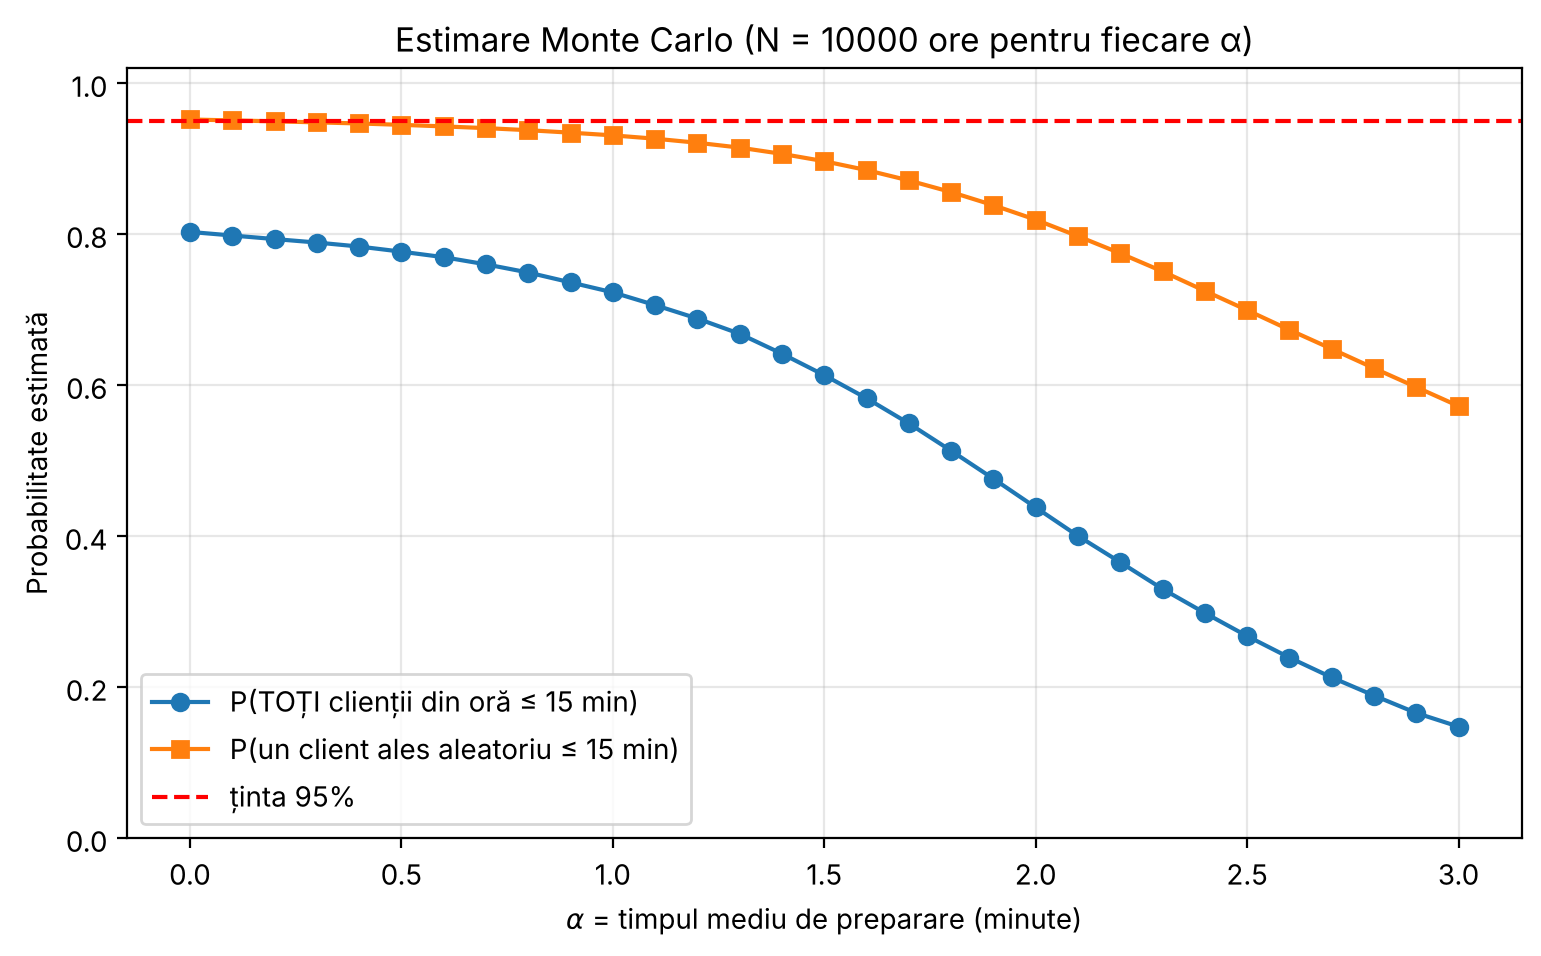

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(alfe, rezultate_toti, "o-", label="P(TOTI clientii din ora <= 15 min)")
plt.plot(alfe, rezultate_client, "s-", label="P(un client ales aleatoriu <= 15 min)")
plt.axhline(0.95, color="red", linestyle="--", label="tinta 95%")
plt.xlabel(r"$\alpha$ = timpul mediu de preparare (minute)")
plt.ylabel("Probabilitate estimata")
plt.title(f"Estimare Monte Carlo (N = {N_SIM} ore pentru fiecare alpha)")
plt.ylim(0, 1.02); plt.grid(alpha=0.3); plt.legend(); plt.show()

In [ ]:
# Care este cel mai mare alfa pentru care P(toti <= 15) >= 0.95?
bune = alfe[rezultate_toti >= 0.95]
if len(bune) > 0:
    print("Cel mai mare alfa cu P(toti) >= 0.95:", bune.max())
else:
    print("NU exista niciun alfa in grila pentru care P(toti clientii <= 15 min) >= 0.95.")
    print(f"Maximul obtinut (alfa ~ 0) este doar {rezultate_toti.max():.3f}.")

NU exista niciun alfa in grila pentru care P(toti clientii <= 15 min) >= 0.95.
Maximul obtinut (alfa ~ 0) este doar 0.803.


Chiar si atunci cand bucataria e practic instantanee ($\alpha \approx 0$), probabilitatea ca **toti** clientii dintr-o ora sa fie serviti in 15 minute este doar **~ 0.80**. Prin urmare, cu parametrii din enunt, **nu exista nicio valoare a lui $\alpha$ pentru care aceasta probabilitate sa ajunga la 95%**.

**De ce?** Strangularea (gatul de sticla) este **casa**, nu bucataria:
- clientii vin in medie la 3 minute, iar plata dureaza in medie 2 minute, deci casa e ocupata cam $\rho = \lambda \cdot 2 = \frac{1}{3}\cdot 2 = \frac{2}{3} \approx 67\%$ din timp;
- timpii sunt exponentiali (foarte variabili), deci uneori vin mai multi clienti la rand sau o plata dureaza mult, si se formeaza coada;
- intr-o ora sunt ~20 de clienti, iar e suficient ca **unul singur** sa astepte peste 15 minute ca ora sa fie "ratata".

Daca ar fi doar casa (ca o coada M/M/1), timpul in sistem pe termen lung ar fi exponential cu rata $\mu - \lambda = \frac12 - \frac13 = \frac16$ pe minut, deci $P(T > 15) \approx e^{-15/6} \approx 0.08$ **pentru fiecare client**. Cu ~20 de clienti pe ora, sansa ca macar unul sa depaseasca 15 minute e mare - de aici cele ~20% ore ratate. Bucataria nu face decat sa adauge timp suplimentar, deci probabilitatea poate doar sa scada cand $\alpha$ creste.

In [ ]:
# Verificare a explicatiei: probabilitatea teoretica (M/M/1 stationar) ca UN client sa stea > 15 min doar la casa
mu, lam = 1/2, 1/3
print("P(T_casa > 15) pe termen lung ~", round(np.exp(-(mu - lam) * 15), 4))

P(T_casa > 15) pe termen lung ~ 0.0821


### Varianta "client ales aleatoriu" (doar pentru comparatie)
Daca cerinta ar fi fost pentru **un client ales aleatoriu** (interpretare pe care enuntul o exclude explicit, dar e utila ca reper), cautam cel mai mare $\alpha$ cu $P(T \le 15) \ge 0.95$. Rafinam grila pe intervalul $[0, 0.6]$ din 0.025 in 0.025, cu $N = 20\,000$ ore.

In [ ]:
alfe_fine = np.round(np.arange(0.025, 0.601, 0.025), 3)
p_client_fine = []
for alfa in alfe_fine:
    _, p_client, _, _ = estimeaza(alfa, 20_000, SEED)
    p_client_fine.append(p_client)
    print(f"alfa = {alfa:.3f}:  P(un client <= 15) = {p_client:.4f}")
p_client_fine = np.array(p_client_fine)

bune = alfe_fine[p_client_fine >= 0.95]
alfa_client = bune.max() if len(bune) > 0 else None
print("\nCel mai mare alfa cu P(un client <= 15) >= 0.95:", alfa_client, "minute")

alfa = 0.025:  P(un client <= 15) = 0.9525


alfa = 0.050:  P(un client <= 15) = 0.9522


alfa = 0.075:  P(un client <= 15) = 0.9520


alfa = 0.100:  P(un client <= 15) = 0.9517


alfa = 0.125:  P(un client <= 15) = 0.9514


alfa = 0.150:  P(un client <= 15) = 0.9511


... (14 outputs left out)

alfa = 0.525:  P(un client <= 15) = 0.9456


alfa = 0.550:  P(un client <= 15) = 0.9451


alfa = 0.575:  P(un client <= 15) = 0.9445


alfa = 0.600:  P(un client <= 15) = 0.9439

Cel mai mare alfa cu P(un client <= 15) >= 0.95: 0.225 minute


Pentru un client ales aleatoriu, pragul de 95% se atinge doar pentru $\alpha$ foarte mic, aproximativ **0.2 minute (grila da 0.225 min, adica ~13 secunde)**. Si aici, diferentele fata de 0.95 sunt foarte mici (de ordinul erorii Monte Carlo), deci valoarea e aproximativa.

**Concluzie la b):** cu o singura casa care proceseaza in medie 30 de clienti/ora la o cerere de 20/ora, cerinta "toti clientii serviti in 15 minute in 95% din ore" **nu poate fi indeplinita** indiferent cat de rapida e bucataria. Ar trebui imbunatatita casa (de ex. a doua casa sau plata mai rapida). Mai jos aratam, ca exemplu, ce se intampla daca plata ar dura in medie 1 minut.

In [ ]:
# Experiment suplimentar: ce ar fi daca plata ar dura in medie 1 minut in loc de 2?
media_plata_original = media_plata
media_plata = 1.0
for alfa in [0.5, 1.0, 1.5, 2.0]:
    p_toti, _, _, _ = estimeaza(alfa, 5000, SEED)
    print(f"[plata medie 1 min] alfa = {alfa}:  P(toti <= 15) = {p_toti:.3f}")
media_plata = media_plata_original   # revenim la valoarea din enunt!
print("\nmedia_plata a revenit la", media_plata, "minute")

[plata medie 1 min] alfa = 0.5:  P(toti <= 15) = 0.999
[plata medie 1 min] alfa = 1.0:  P(toti <= 15) = 0.995


[plata medie 1 min] alfa = 1.5:  P(toti <= 15) = 0.939
[plata medie 1 min] alfa = 2.0:  P(toti <= 15) = 0.734

media_plata a revenit la 2 minute


## c) Timpul mediu de la sosire pana la primirea mancarii

Cum nu exista un $\alpha$ care sa satisfaca cerinta pentru toti clientii, raportam rezultatele pentru:
1. $\alpha \approx 0.225$ minute - valoarea obtinuta cu criteriul "client ales aleatoriu";
2. $\alpha \to 0$ - cel mai bun caz posibil (probabilitatea maxima la nivel de ora);
3. cateva valori mai realiste ($\alpha = 1, 2$), pentru comparatie.

Estimam:
- **timpul mediu total** $\bar T$ = media lui (primeste mancarea - sosire), peste toti clientii din toate orele simulate;
- **timpul mediu de asteptare efectiva** $\bar W$ = media timpului petrecut doar la cozi (fara plata si gatit).

In [ ]:
alfe_raport = [alfa_client if alfa_client is not None else 0.2, 0.001, 1.0, 2.0]
print(f"{'alfa':>6} | {'P(toti<=15)':>11} | {'timp mediu total':>16} | {'asteptare medie':>15} | {'plata+gatit medii':>17}")
for alfa in alfe_raport:
    p_toti, p_client, T, W = estimeaza(alfa, N_SIM, SEED)
    print(f"{alfa:>6.3f} | {p_toti:>11.3f} | {T.mean():>12.2f} min | {W.mean():>11.2f} min | {(T - W).mean():>13.2f} min")

  alfa | P(toti<=15) | timp mediu total | asteptare medie | plata+gatit medii


 0.225 |       0.793 |         5.24 min |        3.01 min |          2.22 min


 0.001 |       0.803 |         5.00 min |        3.00 min |          2.00 min


 1.000 |       0.723 |         6.42 min |        3.43 min |          3.00 min


 2.000 |       0.438 |         9.57 min |        5.57 min |          4.00 min


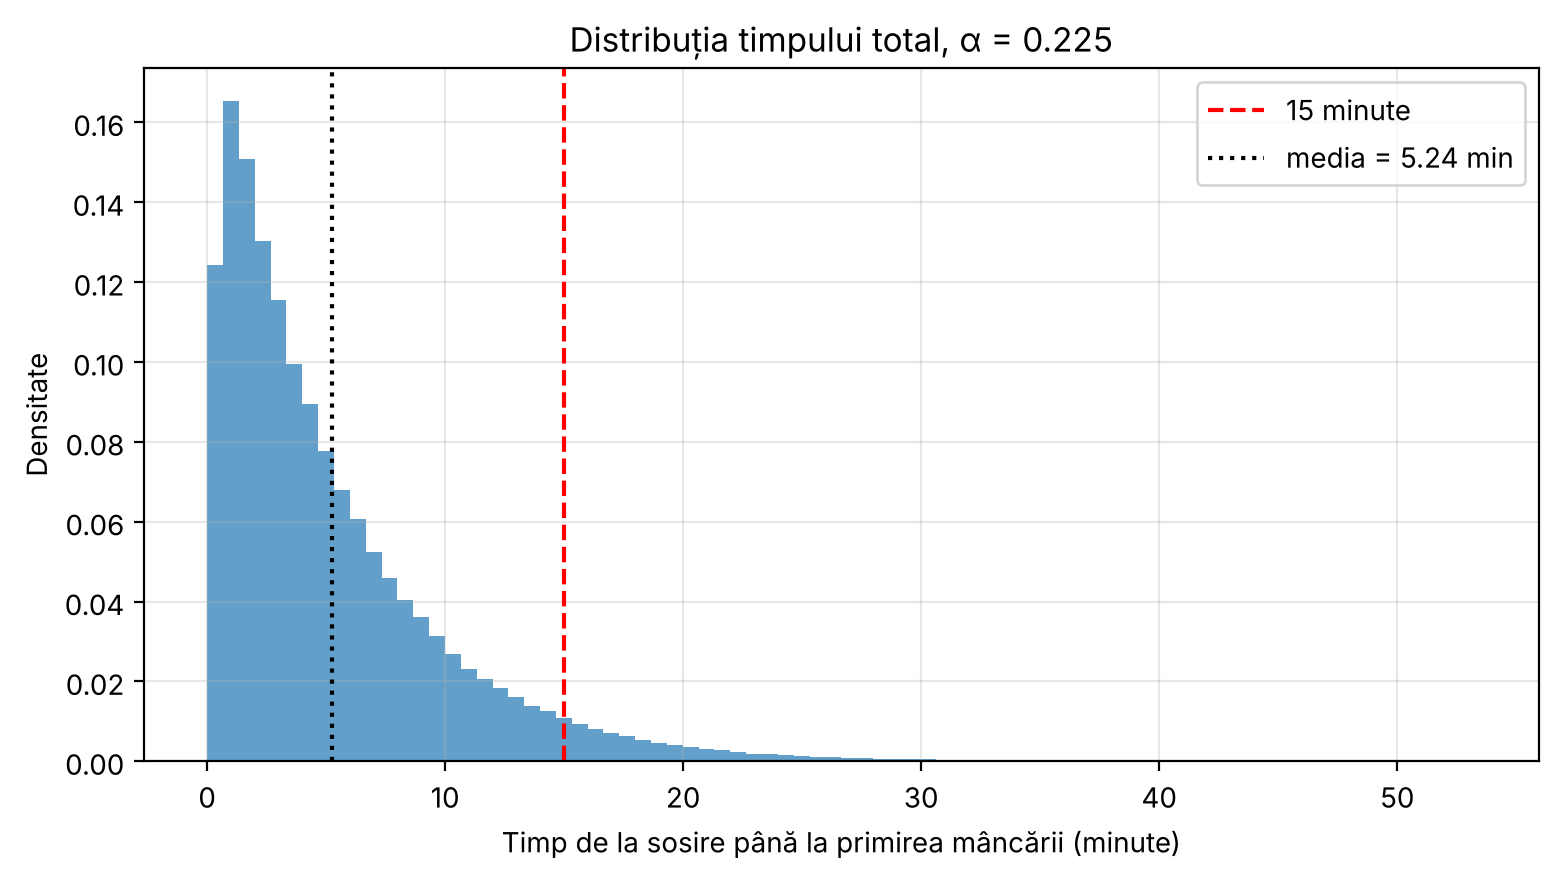

In [ ]:
# Histograma
alfa_c = alfe_raport[0]
_, _, T, W = estimeaza(alfa_c, N_SIM, SEED)
plt.figure(figsize=(9, 4.5))
plt.hist(T, bins=80, density=True, alpha=0.7)
plt.axvline(PRAG, color="red", linestyle="--", label="15 minute")
plt.axvline(T.mean(), color="black", linestyle=":", label=f"media = {T.mean():.2f} min")
plt.xlabel("Timp de la sosire pana la primirea mancarii (minute)")
plt.ylabel("Densitate"); plt.title(f"Distributia timpului total, alpha = {alfa_c}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretare:** pentru $\alpha \approx 0.225$ minute, un client asteapta in medie aproximativ **5.2 minute** de la sosire pana primeste mancarea, din care cam **3 minute** sunt asteptare la coada (in principal la casa), iar restul de ~2.2 minute sunt plata (~ 2 min) si gatitul (~ 0.2 min). Pentru $\alpha = 1$ si $\alpha = 2$ timpul mediu creste la circa 6.4 si 9.6 minute. Media e mult sub 15 minute, dar coada lunga a distributiei (vezi histograma) face ca, intr-o ora cu ~20 de clienti, sa apara des cel putin un client care depaseste 15 minute.

## d) Detalii despre simulare si variabilitatea rezultatelor



In [ ]:
print("Estimarea P(toti <= 15) pentru alfa = 1, cu seminte diferite (N = 5000):")
valori = []
for s in [1, 2, 3, 4, 5]:
    p_toti, _, _, _ = estimeaza(1.0, 5000, seed=s)
    valori.append(p_toti)
    print(f"  samanta {s}: {p_toti:.4f}")
p_bar = np.mean(valori)
print(f"\nDeviatia standard intre rulari: {np.std(valori, ddof=1):.4f}")
print(f"Eroarea standard teoretica:     {np.sqrt(p_bar * (1 - p_bar) / 5000):.4f}")

Estimarea P(toti <= 15) pentru alfa = 1, cu seminte diferite (N = 5000):
  samanta 1: 0.7398
  samanta 2: 0.7348


  samanta 3: 0.7428


  samanta 4: 0.7308


  samanta 5: 0.7442

Deviatia standard intre rulari: 0.0056
Eroarea standard teoretica:     0.0062
